# Reconstruction-based ECG anomaly detection

Can a model trained on normal beats assign larger reconstruction errors to other classes?

I train an autoencoder using class 1 beats only. A normal validation subset sets the score threshold, and a one-class SVM provides a reference. Evaluation reports discrimination and the error trade-off at that threshold.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    Trainer,
    TrainConfig,
    plot_history,
    seed_everything,
    split_tensors,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "04_ecg_anomaly_detection"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Normal-only training

This file contains beat labels, not patient identifiers. I first stratify all beats into train, validation and test subsets, then retain normal beats only for fitting. The scaler is fitted on normal training beats. The threshold is the 95th percentile of normal validation errors, which targets a validation false-positive rate near 5%.

In [5]:
from deep_projects.data import ecg_data
from deep_projects.models import DenseAutoencoder
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
)

signals, labels = ecg_data(root / "data" / "ECG5000.csv")
split = split_tensors(signals, labels)
normal_train = split.train.tensors[0][split.train.tensors[1] == 0]
scaler = StandardScaler().fit(normal_train.numpy())
normal_train = torch.tensor(scaler.transform(normal_train.numpy()), dtype=torch.float32)
validation = torch.tensor(
    scaler.transform(split.validation.tensors[0].numpy()), dtype=torch.float32
)
test = torch.tensor(
    scaler.transform(split.test.tensors[0].numpy()), dtype=torch.float32
)
validation_normal = validation[split.validation.tensors[1] == 0]
train_loader = DataLoader(TensorDataset(normal_train, normal_train), 64, shuffle=True)
validation_loader = DataLoader(TensorDataset(validation_normal, validation_normal), 64)
print(
    {
        "normal_train": len(normal_train),
        "normal_validation": len(validation_normal),
        "test": len(test),
    }
)

{'normal_train': 1751, 'normal_validation': 584, 'test': 1000}


## Reconstruction score

The anomaly score is mean squared reconstruction error per beat, $s(x)=\|x-\hat{x}\|_2^2/140$. Larger scores indicate a poorer match to the normal training distribution. The normal-only validation loss selects the model checkpoint.

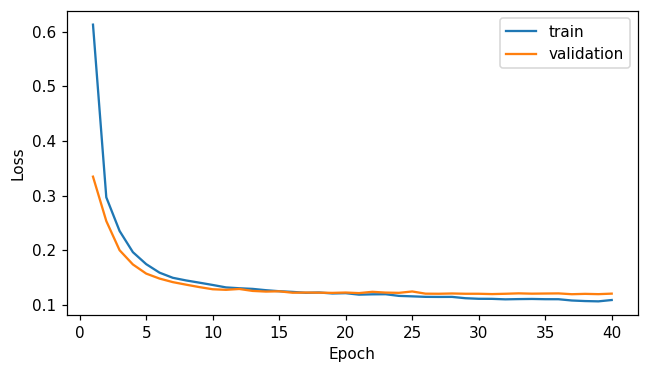

In [7]:
model = DenseAutoencoder(latent=8)
history = Trainer(model, nn.MSELoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")
model.eval()
with torch.inference_mode():
    validation_scores = (
        (model(validation_normal) - validation_normal).square().mean(-1).numpy()
    )
    test_scores = (model(test) - test).square().mean(-1).numpy()
threshold = float(np.quantile(validation_scores, 0.95))
anomaly_labels = (split.test.tensors[1] != 0).numpy().astype(int)
svm = OneClassSVM(nu=0.05, gamma="scale").fit(normal_train.numpy())
svm_validation = -svm.decision_function(validation_normal.numpy())
svm_test = -svm.decision_function(test.numpy())
svm_threshold = float(np.quantile(svm_validation, 0.95))

## Ranking and threshold metrics

ROC AUC evaluates all score thresholds. Average precision depends on the test anomaly prevalence and is useful when one class is rare. Precision and recall below use the fixed normal-validation threshold. A false positive is a normal beat flagged as anomalous.

In [9]:
rows = []
for name, scores, cutoff in [
    ("autoencoder", test_scores, threshold),
    ("one_class_svm", svm_test, svm_threshold),
]:
    predictions = scores > cutoff
    normal = anomaly_labels == 0
    rows.append(
        {
            "method": name,
            "roc_auc": float(roc_auc_score(anomaly_labels, scores)),
            "average_precision": float(average_precision_score(anomaly_labels, scores)),
            "precision": float(
                precision_score(anomaly_labels, predictions, zero_division=0)
            ),
            "recall": float(recall_score(anomaly_labels, predictions, zero_division=0)),
            "normal_false_positive_rate": float(predictions[normal].mean()),
            "threshold": cutoff,
        }
    )
print(pd.DataFrame(rows))
results = {
    "test": rows,
    "anomaly_prevalence": float(anomaly_labels.mean()),
    "normal_class": 1,
    "patient_split_available": False,
}

          method   roc_auc  ...  normal_false_positive_rate  threshold
0    autoencoder  0.989314  ...                    0.063356   0.297794
1  one_class_svm  0.986285  ...                    0.051370   0.258846

[2 rows x 7 columns]


## Score distribution and largest errors

Score overlap explains why one threshold cannot perfectly separate classes. The largest-error examples can reveal unusual morphology or poor reconstruction; they should be inspected before assigning a biological explanation.

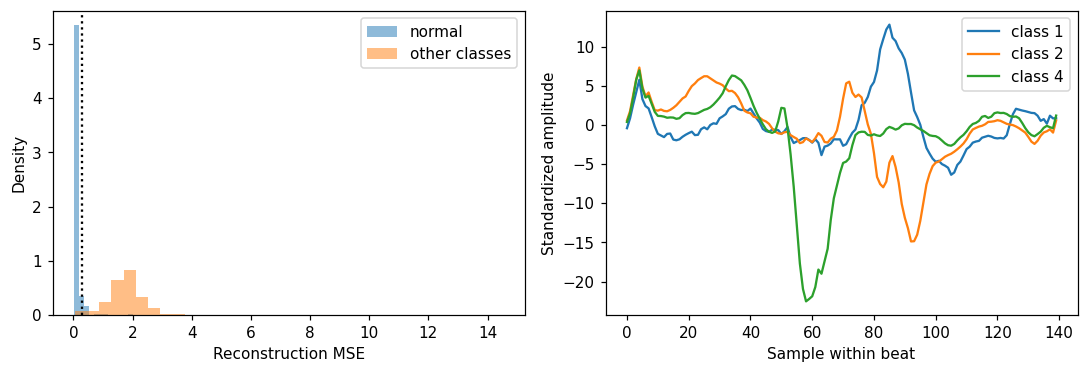

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, name in [(0, "normal"), (1, "other classes")]:
    axes[0].hist(
        test_scores[anomaly_labels == label],
        bins=35,
        alpha=0.5,
        label=name,
        density=True,
    )
axes[0].axvline(threshold, color="black", linestyle=":")
axes[0].legend()
axes[0].set(xlabel="Reconstruction MSE", ylabel="Density")
hardest = np.argsort(test_scores)[-3:]
for index in hardest:
    axes[1].plot(
        test[index].numpy(), label=f"class {int(split.test.tensors[1][index]) + 1}"
    )
axes[1].set(xlabel="Sample within beat", ylabel="Standardized amplitude")
axes[1].legend()
fig.tight_layout()
fig.savefig(output / "anomalies.png", dpi=140)
plt.show()

## Reading the result

This treats every non-class-1 beat as an anomaly. It is a dataset label convention, not a clinical decision rule. The threshold controls validation behavior and may produce a different false-positive rate on test data.

Recorded run: The recorded autoencoder ROC AUC was 0.9893. At the normal-validation threshold, its test false-positive rate was 6.34%. The one-class SVM achieved ROC AUC 0.9863 and a lower false-positive rate at its own threshold. These are beat-level dataset results.

In [13]:
result_path = root / "results" / "04_ecg_anomaly_detection.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/04_ecg_anomaly_detection.json


## Next experiment

Create a patient-separated dataset when identifiers are available. Compare thresholds chosen from normal data with thresholds selected using a small labeled validation set, keeping the final test set unchanged.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_7.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.